In [1]:
# test the 4FGL catalog for covariate shift

In [1]:
import numpy as np
import random
import pandas as pd
from matplotlib import pyplot
from astropy.io import fits
from scipy.stats import binom, kstest
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

from sklearn.mixture import GaussianMixture

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.21.5


In [2]:
def get_neff(w):
    return np.sum(w)**2/np.sum(w**2)

In [3]:
if 1:
    import importlib
    importlib.reload(util);


In [5]:
# generic inputs
cat_name = '4FGL_DR4' # '4FGL_DR3'
if cat_name == '4FGL_DR4':
    baseline_case = '4FGL_DR4_RF_RF'
    case = '4FGL_DR4_RF_RF'

baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'
# generic inputs
cdict = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)


cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')

alg = cdict.get('class_alg', 'RF')
train_weighting = cdict.get('train_weighting')
test_weighting = cdict.get('test_weighting')
weighted = (train_weighting is not None) or (test_weighting is not None)
#oversample_factor = 1 # used for 'resampled' training and testing
max_sample = int(cdict.get('max_sample', 7))
test_frac = float(cdict.get('test_frac', 0.3))
nav = int(cdict.get('nav', 10))


tree_alg = cdict.get('sep_model', 'GMM')
#tree_alg = 'RF' # 'stat', 'GMM', 'RF', '4class', '2class', 'RF_aakash'


# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
cat_tree = list(tree_cat_dict.keys())

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
assoc_classes = list(nsrc_dict.keys())

# algorithm description string
pars_dict = {'RF':{'max_depth': 15, 'n_estimators': 50,},
             'NN_SK':{'activation': 'relu', 'hidden_layer_sizes': (20, 10,),},
             'BDT':{'max_depth': 15},
             'LR':{'max_iter':1000},
             'NN': {'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 1000, 'activation': 'tanh', 
                       'hidden_layer_sizes': [20, 10], 
                       'nfeatures': len(features), 'classes': None, 'verbose': 0,
                       'drop_rate': 0.0,
                      'validation_split': None}
            }
alg_descr = util.get_alg_descr(cdict, pars_dict)


# specific inputs
#folder = folder_out
nca = 6
ncu = 6
save_plots = 1
copy2tex = 0
class1 = '00' # class to plot ROC, precision and recall
lss = ['-', '--', '-.', ':', (0, (5, 4)), (0, (4, 5, 1, 5)), (0, (3, 5, 1, 5, 1, 5))]
markers = ['s', 'o', 'd', '<', '>', 'v', '^']

if tree_alg == '2class':
    title_dict = {'00': 'Extragalactic', '01': 'Galactic'}

nclasses = len(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

# file to save weights
save_weights = 1
recalculate = 0
weights_fn = util.get_weights_fn(cdict)

plots_folder = root_folder + 'plots/cov_shift_%s_%s/' % (cat_name, feature_mode)
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)

paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper/cov_shift_paper_main/'


assoc_classes = []
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)
nsrc_dict = {cl:np.sum(xdf[class_name] == cl) for cl in assoc_classes}

top_features = features
if tree_alg == 'GMM':
    #top_features = ['LP_SigCurv', 'LP_index1000MeV', 'log10(Variability_Index)',\
    #'log10(Energy_Flux100)', 'log10(Unc_Energy_Flux100)', 'LP_beta',]
    #top_features = ['log10(Unc_Energy_Flux100)', 'LP_beta', 'LP_SigCurv',]
    #top_features = ['log10(Unc_Energy_Flux100)', 'LP_beta', ]
    top_features = features
elif tree_alg == '4class':
    #top_features = ['log10(Unc_Energy_Flux100)', 'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)']
    top_features = features
    
use_features = top_features
#use_features = features
paper_features = ['sin(GLAT)', 'log10(Signif_Avg)', 'log10(Variability_Index)', 'LP_beta']

fig_width = 7  # width in inches
fig_height = 5    # height in inches
fig_size =  [fig_width, fig_height]
fig_pars_dict = {'fig_size': fig_size, 'legend.fontsize':12, 'legend.labelspacing':0.3}
putil.setup_figure_pars(pars_dict=fig_pars_dict)
pyplot.rcParams['legend.labelspacing'] = 0.3

plot_descr = '%s_classif%s_show%s' % (tree_alg, alg, class1)

for key in tree_cat_dict:
    cls = tree_cat_dict[key]
    clf_mask = util.get_cl_mask(cls, xdf, cname=class_name)
    print('%s (%i sources)' % (util.cl_list2str(cls), sum(clf_mask)))
print(use_features)
print(weights_fn)

bcu, sey, agn, nov (1641 sources)
glc, msp (213 sources)
spp, hmb, pwn, sfr, psr (303 sources)
bin, css, fsrq, lmb, nlsy1, ssrq (854 sources)
bll (1490 sources)
snr, sbg, rdg, gal, gc (113 sources)
['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)', 'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV', 'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)']
../../data_out//weights/weights_4FGL_DR4_all_features.csv


In [6]:
all_cls = []
for cls in tree_cat_dict.values():
    all_cls.extend(cls)
clf_mask = util.get_cl_mask(all_cls, xdf, cname=class_name)
unas_mask = (xdf[class_name] == 'unas') | (xdf[class_name] == 'unk') 
#unas_mask = ~clf_mask
sum(unas_mask), sum(~unas_mask), sum(clf_mask), len(clf_mask)

(2577, 4614, 4614, 7191)

sin(GLAT) 1.5543122344752192e-15
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_sin(GLAT).pdf
cos(GLON) 1.5543122344752192e-15
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_cos(GLON).pdf
sin(GLON) 5.0993653744058065e-12
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_sin(GLON).pdf
log10(Energy_Flux100) 8.413270080609436e-13
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_log10(Energy_Flux100).pdf
log10(Unc_Energy_Flux100) 1.5543122344752192e-15
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_log10(Unc_Energy_Flux100).pdf
log10(Signif_Avg) 1.5543122344752192e-15
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_log10(Signif_Avg).pdf
LP_index1000MeV 1.5543122344752192e-15
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_LP_index1000MeV.pdf
LP_beta 1.5543122344752192e-15
save figure

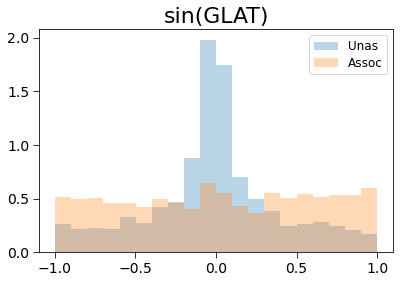

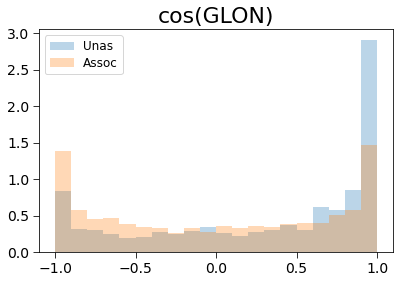

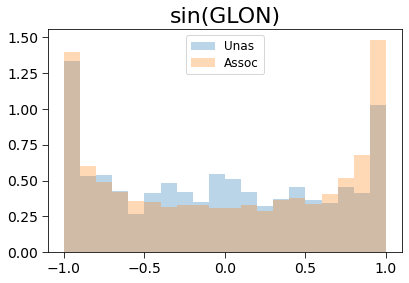

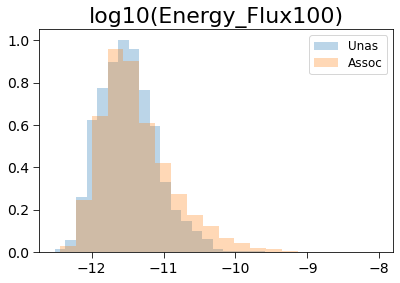

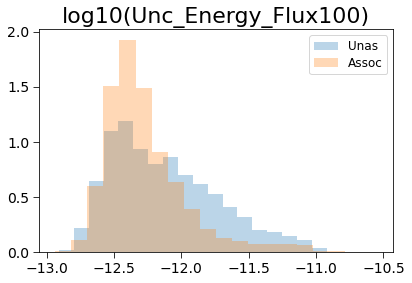

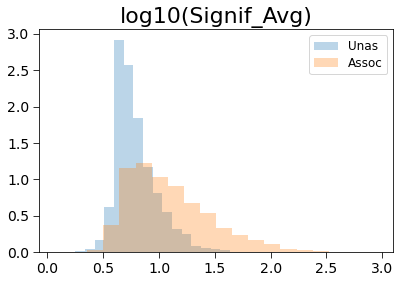

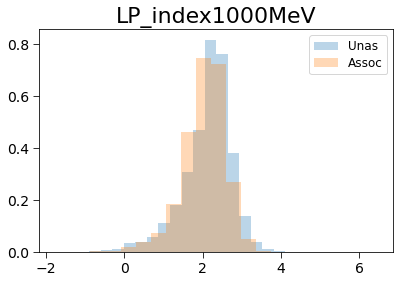

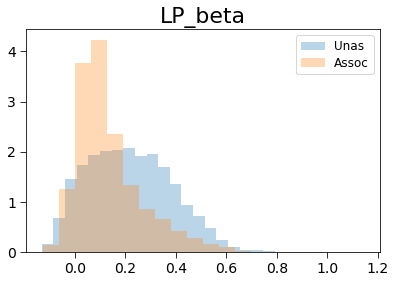

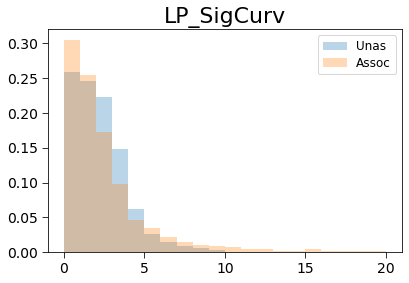

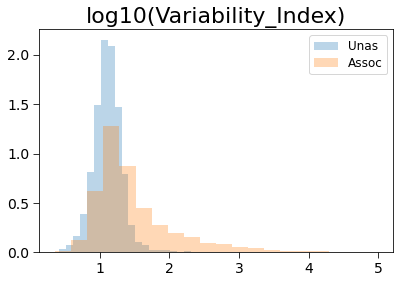

In [7]:
for cname in top_features:
    xu = np.array(xdf[cname][unas_mask], dtype=float)
    #xa = np.array(xdf[cname][~unas_mask], dtype=float)
    xa = np.array(xdf[cname][clf_mask], dtype=float)
    pvalue = kstest(xu, xa)[1]
    print(cname, pvalue)
    
    pyplot.figure()
    if cname == 'LP_SigCurv':
        bins = np.linspace(0, 20, 21)
    else:
        bins = 20
    pyplot.hist(xu, density=True, alpha=0.3, label='Unas', bins=bins)
    pyplot.hist(xa, density=True, alpha=0.3, label='Assoc', bins=bins)
    pyplot.legend()
    pyplot.title(cname)
    
    if save_plots:
        fn = '%sass_vs_unass_%s.pdf' % (plots_folder, cname)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)


In [8]:

if save_weights or recalculate or (not os.path.isfile(weights_fn)):
    # GMM model of assoc and unas sources
    mdla = GaussianMixture(n_components=nca, init_params='random', n_init=3, random_state=4);
    #mdla.fit(xdf[top_features][~unas_mask])
    mdla.fit(xdf[top_features][clf_mask])
    mdlu = GaussianMixture(n_components=ncu, init_params='random', n_init=3, random_state=4);
    mdlu.fit(xdf[top_features][unas_mask])
    mdlu_probs = np.exp(mdlu.score_samples(xdf[top_features])) # score_samples - log likelihood for each sample
    mdla_probs = np.exp(mdla.score_samples(xdf[top_features]))
    
    weights_df = pd.DataFrame(index=xdf.index, columns=['assoc_pdf', 'unas_pdf'], data=0.)
    weights_df['assoc_pdf'] = mdla_probs
    weights_df['unas_pdf'] = mdlu_probs
    if save_weights:
        print('save weights to file')
        print(weights_fn)
        weights_df.to_csv(weights_fn)
else:
    weights_df = pd.read_csv(weights_fn, index_col=0)
    mdlu_probs = weights_df['unas_pdf']
    mdla_probs = weights_df['assoc_pdf']


save weights to file
../../data_out//weights/weights_4FGL_DR4_all_features.csv


In [9]:
np.sum(mdlu_probs < 0.01), np.sum(mdlu_probs > 0.01)

(2305, 4886)

In [10]:
gumask = mdlu_probs > 0.0000001
gamask = mdla_probs > 0.0000001
print(sum(~gumask & unas_mask), sum(~gumask & ~unas_mask))
print(sum(~gamask & unas_mask), sum(~gamask & ~unas_mask))

4 505
11 23


In [11]:
np.min(mdla_probs), max_sample

(1.1171143677713077e-30, 7)

In [12]:
binary = False
max_sample = 7
sample_ratio = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=binary, max_sample=max_sample)
if binary:
    sample_ratio_bin = sample_ratio
else:
    sample_ratio_bin = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=True, max_sample=max_sample-0.01)

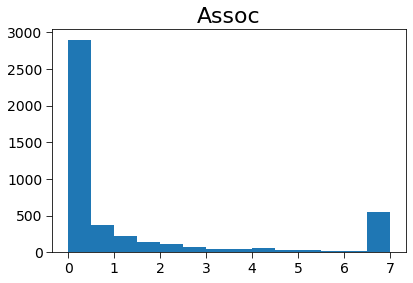

In [13]:
res = pyplot.hist(sample_ratio[clf_mask], bins=np.linspace(0, max_sample, 2 * max_sample + 1));
pyplot.title('Assoc');

save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/effective_sample_number.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/sample_weights.pdf


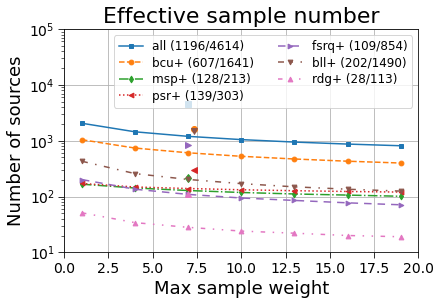

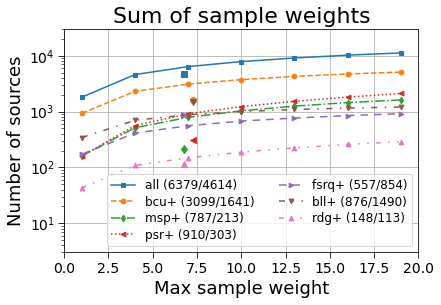

In [14]:
# Effective number of points
msize = 6
nass = np.sum(clf_mask)
nunas = np.sum(~clf_mask)
step = 3
ms_min = 1
ms_max = ms_min + 6 * step
mss = np.arange(ms_min, ms_max + 1, step)
neff_dict = {'all':np.zeros_like(mss)}
nw_dict = {'all':np.zeros_like(mss)}
clf_masks = {}
sfactor = 1.
for key in tree_cat_dict:
    cls = tree_cat_dict[key]
    clf_masks[key] = util.get_cl_mask(cls, xdf, cname=class_name)
    neff_dict[key] = np.zeros_like(mss)
    nw_dict[key] = np.zeros_like(mss)
for i, ms in enumerate(mss):
    sample_ratio_loc = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=binary, max_sample=ms)
    neff_dict['all'][i] = get_neff(sample_ratio_loc[clf_mask])
    nw_dict['all'][i] = np.sum(sample_ratio_loc[clf_mask]) * sfactor
    for key in tree_cat_dict:
        neff_dict[key][i] = get_neff(sample_ratio_loc[clf_masks[key]])
        nw_dict[key][i] = np.sum(sample_ratio_loc[clf_masks[key]]) * sfactor

nsrc_df = util.nsrc_dict2df(nsrc_dict)
pyplot.figure()
for i, key in enumerate(neff_dict.keys()):
    cls = tree_cat_dict.get(key, 'all')
    ind = np.argmin(np.abs(mss - max_sample))
    neff = neff_dict[key][ind]
    nw = nw_dict[key][ind]
    if cls == 'all':
        nsrc = nass
        label = 'all (%i/%i)' % (neff, nsrc) 
    else:
        nsrc = np.sum([nsrc_dict[cl] for cl in cls])
        label = '%s+ (%i/%i)' % (util.get_max_class(cls, nsrc_df), neff, nsrc)
    p = pyplot.semilogy(mss, neff_dict[key], label=label, ls=lss[i], marker=markers[i], markersize=msize*0.8)
    color = p[0].get_color()
    pyplot.plot(max_sample + 0.3*(i%2), nsrc, color=color, marker=markers[i], markersize=msize)
pyplot.legend(loc='upper right', ncol=2)
pyplot.xlim(ms_min - 1, ms_max + 1)
pyplot.ylim(10, 1.e5)
pyplot.grid()
pyplot.title('Effective sample number')
pyplot.xlabel('Max sample weight')
pyplot.ylabel('Number of sources')

if save_plots:
    fn = '%seffective_sample_number.pdf' % (plots_folder)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if copy2tex and cname in paper_features:
        plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp "%s" "%s"' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

pyplot.figure()
for i, key in enumerate(neff_dict.keys()):
    cls = tree_cat_dict.get(key, 'all')
    ind = np.argmin(np.abs(mss - max_sample))
    neff = neff_dict[key][ind]
    nw = nw_dict[key][ind]
    if cls == 'all':
        nsrc = nass
        label = 'all (%i/%i)' % (nw, nsrc) 
    else:
        nsrc = np.sum([nsrc_dict[cl] for cl in cls])
        
        label = '%s+ (%i/%i)' % (util.get_max_class(cls, nsrc_df), nw, nsrc)
    p = pyplot.semilogy(mss, nw_dict[key], label=label, ls=lss[i], marker=markers[i], markersize=msize*0.8)
    color = p[0].get_color()
    pyplot.plot(max_sample + 0.5*(i%2 - 0.5), nsrc, color=color, marker=markers[i], markersize=msize)

pyplot.xlabel('Max sample weight')
pyplot.ylabel('Number of sources')
pyplot.legend(loc='lower right', ncol=2)
pyplot.xlim(ms_min - 1, ms_max + 1)
pyplot.ylim(3, 3.e4)
pyplot.grid()
pyplot.title('Sum of sample weights')


if save_plots:
    fn = '%ssample_weights.pdf' % (plots_folder)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if copy2tex and cname in paper_features:
        plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp "%s" "%s"' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

#dneff = -(neff_arr[1:] - neff_arr[:-1])
#ddneff = neff_arr[:-2] + neff_arr[2:] - 2 * neff_arr[1:-1]
#pyplot.figure()
#pyplot.plot(mss[:-1], dneff)
#pyplot.figure()
#pyplot.plot(mss[1:-1], ddneff)
#print(get_neff(sample_ratio[clf_mask]), nass, nunas)
#print(np.sum(sample_ratio[clf_mask] > 4.5))

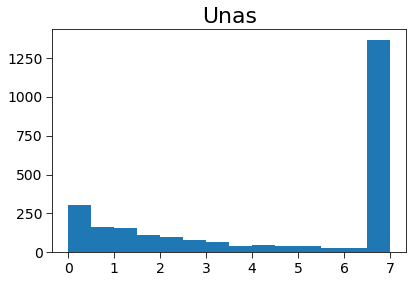

In [15]:
pyplot.hist(sample_ratio[unas_mask], bins=np.linspace(0, max_sample, 2 * max_sample + 1));
pyplot.title('Unas');

save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_sin_GLAT.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_cos_GLON.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_sin_GLON.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_log10_Energy_Flux100.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_log10_Unc_Energy_Flux100.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_log10_Signif_Avg.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_LP_index1000MeV.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_LP_beta.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ass_vs_unass_weighted_LP_SigCurv.pdf
save figure to file: ../../plots/cov_shift_4FGL_DR4_all_

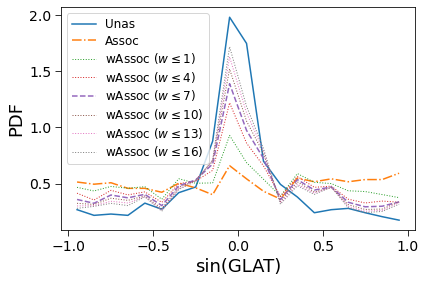

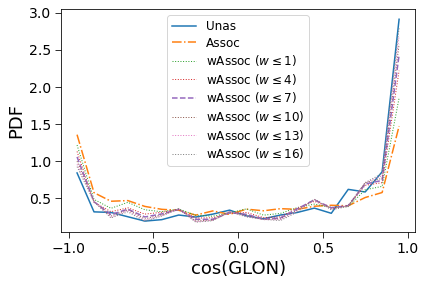

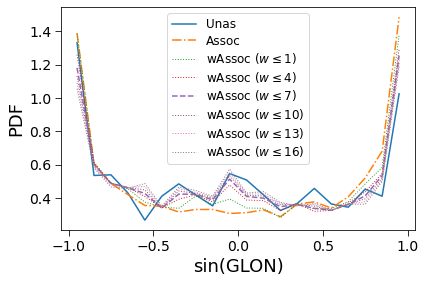

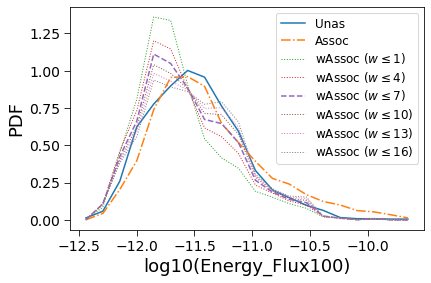

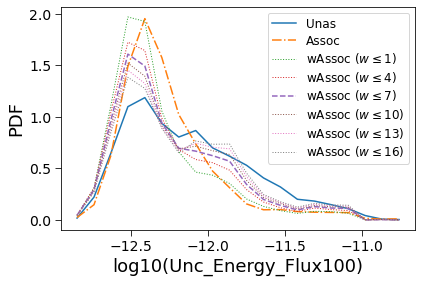

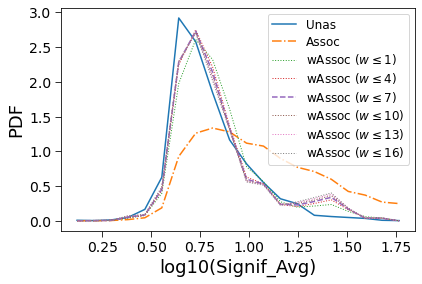

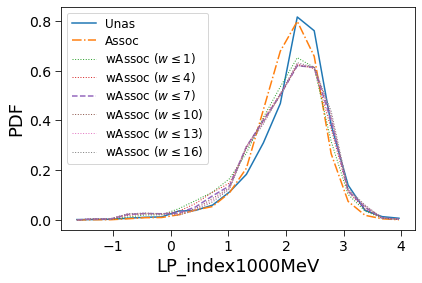

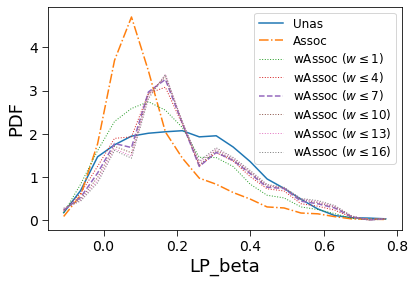

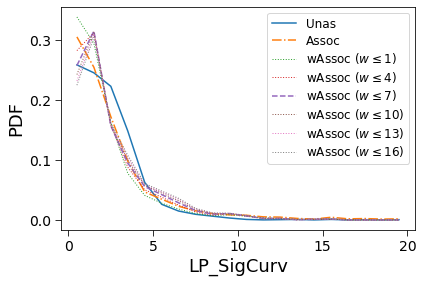

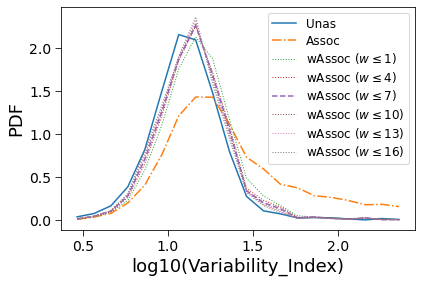

In [16]:
nass = sum(clf_mask)
sinds = random.choices(np.arange(len(xdf))[clf_mask], weights=sample_ratio[clf_mask], k=nass)
#wa = sample_ratio[clf_mask]
mss = np.arange(1, 17, 3)

lwe = 1.5

for cname in top_features:
    xu = xdf[cname][unas_mask]
    xa = xdf[cname][clf_mask]
    
    xaw = xdf[cname][sinds]
    #xaw = random.choices(xa, weights=wa, k=len(xu))
    #pvalue = kstest(xu, xa)[1]
    #print(cname, pvalue)
    
    pyplot.figure()
    if cname == 'LP_SigCurv':
        bins = np.linspace(0, 20, 21)
    else:
        bins = 20
    y, xbins = np.histogram(xu, density=True, bins=bins)
    xc = (xbins[1:] + xbins[:-1]) / 2
    pyplot.plot(xc, y, ls='-', lw=lwe, label='Unas')
    
    y, xbins = np.histogram(xa, density=True, bins=xbins)
    pyplot.plot(xc, y, ls='-.', lw=lwe, label='Assoc')
    for ms in mss:
        sample_ratio_loc = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=binary, max_sample=ms)
        wa = sample_ratio_loc[clf_mask]
        y, xbins = np.histogram(xa, density=True, bins=xbins, weights=wa)
        if ms == max_sample:
            ls = '--'
            lw = lwe
        else:
            ls = ':'
            lw = 1
        pyplot.plot(xc, y, ls=ls, lw=lw, label=r'wAssoc ($w \leq %i$)' % ms)
    
    #y, xbins = np.histogram(xaw, density=True, bins=xbins)
    #pyplot.plot(xc, y, ls=':', label='Assoc sampled')

    pyplot.legend()
    #pyplot.title(cname)
    pyplot.xlabel(cname)
    pyplot.ylabel('PDF')
    
    if save_plots:
        fn = '%sass_vs_unass_weighted_%s.pdf' % (plots_folder, cname)
        fn = fn.replace('(', '_')
        fn = fn.replace(')', '')
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)
        if copy2tex and cname in paper_features:
            plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp "%s" "%s"' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)


In [17]:
# some tests

In [18]:
# training unweighted
cat_tree = list(tree_cat_dict.keys())
horiz_trees = util.get_horiz_trees(cat_tree, mode='add_0')
subtree = horiz_trees[0]

cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict,
                                             include_parents=True)
nodes = subtree


In [19]:
#use_features = top_features # features

ys = np.zeros(ns, dtype='<U6')
#clf_mask = np.zeros(ns, dtype=bool)
for key, cls in cut_subtree.items():
    cls_mask = util.get_cl_mask(cls, xdf, cname=class_name)
    ys[cls_mask] = key
    #clf_mask[cls_mask] = True

X = xdf[use_features][clf_mask]
y = ys[clf_mask]
if 0:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_frac, random_state=0)
else:
    clf_inds = np.arange(len(xdf))[clf_mask]
    clf_inds = list(np.random.permutation(clf_inds).astype(int))
    ntrain = int((1. - test_frac) * sum(clf_mask))
    train_mask = np.zeros(len(xdf), dtype=bool)
    train_mask[clf_inds[:ntrain]] = True
    test_mask = np.zeros(len(xdf), dtype=bool)
    test_mask[clf_inds[ntrain:]] = True

    sample_ratio_train = sample_ratio[train_mask]
    sample_ratio_test = sample_ratio[test_mask]
    X_train = xdf[features][train_mask]
    X_test = xdf[features][test_mask]
    y_train = ys[train_mask]
    y_test = ys[test_mask]

clf = util.get_classifier(alg, pars_dict[alg])
clf.fit(X_train, y_train)


Xt_train = X_train[top_features]
Xt_test = X_test[top_features]

clfw = util.get_classifier(alg, pars_dict[alg])
#mdlu_probs_tr = np.exp(mdlu.score_samples(Xt_train))
#mdla_probs_tr = np.exp(mdla.score_samples(Xt_train))
#sample_ratio_tr = util.get_sample_ratio(mdlu_probs_tr, mdla_probs_tr, binary=binary, max_sample=max_sample)
sample_ratio_tr = sample_ratio_train
clfw.fit(X_train, y_train, sample_weight=sample_ratio_tr)

RandomForestClassifier(max_depth=15, max_features='sqrt', n_estimators=50)

In [20]:
#mdlu_probs_ts = np.exp(mdlu.score_samples(Xt_test))
#mdla_probs_ts = np.exp(mdla.score_samples(Xt_test))
#sample_ratio_ts = util.get_sample_ratio(mdlu_probs_ts, mdla_probs_ts, binary=binary, max_sample=max_sample)
sample_ratio_ts = sample_ratio_test
if binary:
    sample_ratio_ts_bin = sample_ratio_ts
else:
    mdlu_probs_ts = mdlu_probs[test_mask]
    mdla_probs_ts = mdla_probs[test_mask]
    sample_ratio_ts_bin = util.get_sample_ratio(mdlu_probs_ts, mdla_probs_ts, binary=True, max_sample=max_sample-0.01)


In [21]:
#np.sum(sample_ratio_ts), sample_ratio_ts.shape

In [22]:
def accuracy(y_true, y_score, sample_weight=None, thres=0.5):
    if sample_weight is None:
        sample_weight = np.ones_like(y_true).astype(float)
    y_class = np.array(y_score > thres, dtype=float)
    return np.sum((y_class == y_true) * sample_weight) / np.sum(sample_weight)

In [23]:
cthres = 0.5
ind1 = list(clf.classes_).index(class1)
y_true = np.array(y_test == class1).astype(int)
y_score = clf.predict_proba(X_test).T[ind1]
fpr, tpr, thres_ = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)
prec, recall, thres = precision_recall_curve(y_true, y_score)

fprr, tprr, thresr_ = roc_curve(y_true, y_score, sample_weight=sample_ratio_ts)
aucr = roc_auc_score(y_true, y_score, sample_weight=sample_ratio_ts)
precr, recallr, thresr = precision_recall_curve(y_true, y_score, sample_weight=sample_ratio_ts)
#score = clf.score(X_test, y_true)

score = accuracy(y_true, y_score, sample_weight=None, thres=cthres)
#scorer = clf.score(X_test, y_true, sample_weight=sample_ratio_ts)
#scorer = np.sum((y_class == y_true) * sample_ratio_ts) / np.sum(sample_ratio_ts)
scorer = accuracy(y_true, y_score, sample_weight=sample_ratio_ts, thres=cthres)

ind1w = list(clfw.classes_).index(class1)
y_scorew = clfw.predict_proba(X_test).T[ind1w]
fprw, tprw, thresw_ = roc_curve(y_true, y_scorew, sample_weight=sample_ratio_ts)
aucw = roc_auc_score(y_true, y_scorew, sample_weight=sample_ratio_ts)
scorew = accuracy(y_true, y_scorew, sample_weight=sample_ratio_ts, thres=cthres)
precw, recallw, thresw = precision_recall_curve(y_true, y_scorew, sample_weight=sample_ratio_ts)

In [24]:
score, scorer, scorew

(0.8202166064981949, 0.8599697018031143, 0.8459612732462296)

In [25]:
auc, aucw, aucr

(0.8826174033149172, 0.835233511575391, 0.8503208277483891)

In [26]:
ainds = np.arange(len(xdf))[clf_mask] # replace with clf_mask for a subset of assoc sources
test_inds = np.random.choice(ainds, size=int(len(ainds) * test_frac), replace=False, p=None)
train_inds = [i for i in ainds if i not in test_inds]
#test_mask = np.zeros(ns)
#test_mask[test_inds] = 1
#train_mask = np.zeros(ns)
#train_mask[train_inds] = 1

ntr_samples = len(train_inds)
nts_samples = len(test_inds)
train_inds_sam = random.choices(train_inds, weights=sample_ratio[train_inds], k=ntr_samples)
test_inds_sam = random.choices(test_inds, weights=sample_ratio[test_inds], k=nts_samples)
                                
#sinds = random.choices(ainds, weights=sample_ratio[~unas_mask], k=len(xu))

In [27]:
X_trainws = xdf[use_features].iloc[train_inds_sam]
X_testws = xdf[use_features].iloc[test_inds_sam]
y_trainws = ys[train_inds_sam]
y_testws = ys[test_inds_sam]

clfws = util.get_classifier(alg, pars_dict[alg])
clfws.fit(X_trainws, y_trainws)

RandomForestClassifier(max_depth=15, max_features='sqrt', n_estimators=50)

In [28]:
ind1ws = list(clfws.classes_).index(class1)
y_truews = np.array(y_testws == class1).astype(int)
y_scorews = clfws.predict_proba(X_testws).T[ind1ws]
fprws, tprws, thresws_ = roc_curve(y_truews, y_scorews)
aucws = roc_auc_score(y_truews, y_scorews)
scorews = accuracy(y_truews, y_scorews, sample_weight=None, thres=cthres)
precws, recallws, thresws = precision_recall_curve(y_truews, y_scorews)


y_truers = y_truews
y_scorers = clf.predict_proba(X_testws).T[ind1]
fprrs, tprrs, thresrs_ = roc_curve(y_true, y_score, sample_weight=sample_ratio_ts_bin)
aucrs = roc_auc_score(y_true, y_score, sample_weight=sample_ratio_ts_bin)
scorers = accuracy(y_true, y_score, sample_weight=sample_ratio_ts_bin)
precrs, recallrs, thresrs = precision_recall_curve(y_true, y_score, sample_weight=sample_ratio_ts_bin)
print(aucws, aucrs)
print(scorews, scorers)

0.7911798587885543 0.88710407239819
0.8511560693641619 0.9047619047619048


In [29]:
clf_fi = util.get_feature_importances(clf)
clf_fi[:5]

,Feature,Imortance
6,LP_index1000MeV,0.235567
7,LP_beta,0.146885
5,log10(Signif_Avg),0.124001
0,sin(GLAT),0.08294
9,log10(Variability_Index),0.081501


In [30]:
clfw_fi = util.get_feature_importances(clfw)
clfw_fi[:5]

/Users/Dmitry/miniconda3/envs/python3/lib/python3.7/site-packages/sklearn/tree/_classes.py:631: RuntimeWarning: invalid value encountered in true_divide
  return self.tree_.compute_feature_importances()


,Feature,Imortance
0,sin(GLAT),NaN
1,cos(GLON),NaN
2,sin(GLON),NaN
3,log10(Energy_Flux100),NaN
4,log10(Unc_Energy_Flux100),NaN


In [31]:
clfws_fi = util.get_feature_importances(clfws)
clfws_fi[:5]

,Feature,Imortance
0,sin(GLAT),0.130186
4,log10(Unc_Energy_Flux100),0.124867
6,LP_index1000MeV,0.124525
3,log10(Energy_Flux100),0.119798
7,LP_beta,0.107411


save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/ROC_RF_classifRF_show00.pdf


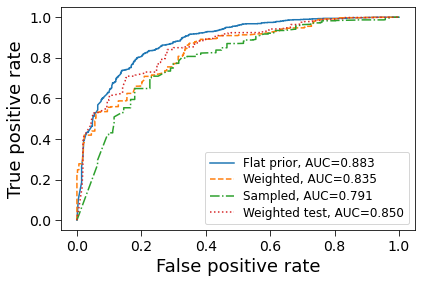

In [32]:
pyplot.figure()
pyplot.plot(fpr, tpr, ls='-', label='Flat prior, AUC=%.3f' % auc)
pyplot.plot(fprw, tprw, ls='--', label='Weighted, AUC=%.3f' % aucw)
pyplot.plot(fprws, tprws, ls='-.', label='Sampled, AUC=%.3f' % aucws)
pyplot.plot(fprr, tprr, ls=':', label='Weighted test, AUC=%.3f' % aucr)
#pyplot.plot(fprrs, tprrs, ls=':', label='Test sampled, AUC=%.3f' % aucrs)
pyplot.legend()
pyplot.xlabel('False positive rate')
pyplot.ylabel('True positive rate')
if tree_alg == '2class':
    pyplot.title(title_dict[class1])

if save_plots:
    fn = '%sROC_%s.pdf' % (plots_folder, plot_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)


In [33]:
add_low_p = False
if add_low_p:
    # compare predictions with subthreshold Bayesian probability
    fn = '../../data_in/gll_psc_v29.fit'
    cat_hdu = fits.open(fn)
    ctab = cat_hdu[1].data 
    pb = ctab['ASSOC_PROB_BAY']
    pbmask = (pb > 0.09) & (pb < 0.8) & (ctab['CLASS2'] != 'unk')
    ctab = ctab[pbmask]

    ns_check = len(ctab)
    snames = np.array([name.strip() for name in ctab['Source_Name']])
    xdf_check = xdf.loc[snames]
    cls = [cl.strip() for cl in ctab['CLASS2']]
    xdf_check['CLASS2'] = cls
    cls2 = list(set(xdf_check['CLASS2']))
    class_name_check = 'CLASS2'
    ys_check = np.zeros(ns_check, dtype='<U6')
    for key, cls in cut_subtree.items():
        cls_mask_check = util.get_cl_mask(cls, xdf_check, cname=class_name_check)
        ys_check[cls_mask_check] = key

    X_check = xdf_check[features]
    ind_check = list(clf.classes_).index(class1)
    y_pred_check = clf.predict_proba(X_check).T[ind_check]
    y_true_check = np.array(ys_check == class1).astype(float)

In [34]:
#util.make_thres_bins(thres, values, nbins=100, eps=1.e-15)
nbins = 20


save figure to file: ../../plots/cov_shift_4FGL_DR4_all_features/prec_recall_RF_classifRF_show00.pdf


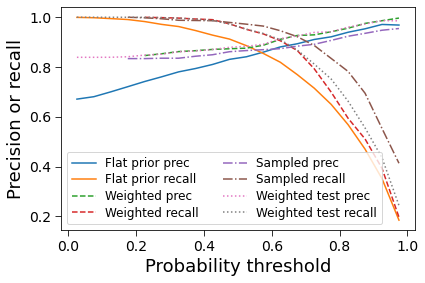

In [35]:
binned_pr = True
pyplot.figure()
# unweighted
if binned_pr:
    precb, thresc, maskp = util.make_thres_bins(thres, prec[:-1], nbins=nbins)
    recallb, thresc, maskr = util.make_thres_bins(thres, recall[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls='-', label='Flat prior prec')
    pyplot.plot(thresc[maskr], recallb, ls='-', label='Flat prior recall')
else:
    pyplot.plot(thres, prec[:-1], ls='-', label='Flat prior prec')
    pyplot.plot(thres, recall[:-1], ls='-', label='Flat prior recall')

# weighted
if binned_pr:
    precb, thresc, maskp = util.make_thres_bins(thresw, precw[:-1], nbins=nbins)
    recallb, thresc, maskr = util.make_thres_bins(thresw, recallw[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls='--', label='Weighted prec')
    pyplot.plot(thresc[maskr], recallb, ls='--', label='Weighted recall')
else:
    pyplot.plot(thresw, precw[:-1], ls='--', label='Weighted prec')
    pyplot.plot(thresw, recallw[:-1], ls='--', label='Weighted recall')


# Sampled
if binned_pr:
    precb, thresc, maskp = util.make_thres_bins(thresws, precws[:-1], nbins=nbins)
    recallb, thresc, maskr = util.make_thres_bins(thresws, recallws[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls='-.', label='Sampled prec')
    pyplot.plot(thresc[maskr], recallb, ls='-.', label='Sampled recall')
else:
    pyplot.plot(thresws, precws[:-1], ls='-.', label='Sampled prec')
    pyplot.plot(thresws, recallws[:-1], ls='-.', label='Sampled recall')
    
# Test weighted
if binned_pr:
    precb, thresc, maskp = util.make_thres_bins(thresr, precr[:-1], nbins=nbins)
    recallb, thresc, maskr = util.make_thres_bins(thresr, recallr[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls=':', label='Weighted test prec')
    pyplot.plot(thresc[maskr], recallb, ls=':', label='Weighted test recall')
else:
    pyplot.plot(thresr, precr[:-1], ls=':', label='Weighted test prec')
    pyplot.plot(thresr, recallr[:-1], ls=':', label='Weighted test recall')
    

# Test sampled
if binned_pr and 0:
    precb, thresc, maskp = util.make_thres_bins(thresrs, precrs[:-1], nbins=nbins)
    recallb, thresc, maskr = util.make_thres_bins(thresrs, recallrs[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls=':', label='Sampled test pred')
    pyplot.plot(thresc[maskr], recallb, ls=':', label='Sampled test recall')
elif 0:
    pyplot.plot(thresrs, precrs[:-1], ls=':', label='Sampled test pred')
    pyplot.plot(thresrs, recallrs[:-1], ls=':', label='Sampled test recall')
    
    
if add_low_p:
    prec_lp, recall_lp, thres_lp = precision_recall_curve(y_true_check, y_pred_check)
    #print(prec.shape, thres.shape)

    precb, thresc, maskp = util.make_thres_bins(thres_lp, prec_lp[:-1], nbins=nbins)
    recallb, thresc, maskr = util.make_thres_bins(thres_lp, recall_lp[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls='-.', label='Prec low p')
    pyplot.plot(thresc[maskr], recallb, ls='-.', label='Recall low p')

pyplot.legend(ncol=2)
pyplot.xlabel('Probability threshold')
pyplot.ylabel('Precision or recall')


if tree_alg == '2class':
    pyplot.title(title_dict[class1])

if save_plots:
    fn = '%sprec_recall_%s.pdf' % (plots_folder, plot_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)


In [36]:
# effective source numbers
sample_ratio_bin_mask = sample_ratio_bin.astype(bool)
#nsrc_dict_w = {cl:np.sum(xdf[class_name][sample_ratio_bin_mask] == cl) for cl in assoc_classes}
nsrc_dict_w = {cl:np.sum((xdf[class_name] == cl)*sample_ratio) for cl in assoc_classes}


In [37]:
nsrc_dict_w

{'bcu': 3055.705574232491,
 'sey': 14.625979198254603,
 'agn': 15.545062302520583,
 'nov': 14.036925622056367,
 'glc': 142.7361841537197,
 'msp': 645.0849657065107,
 'spp': 629.8658213783019,
 'hmb': 36.72163644176418,
 'pwn': 17.457729502625423,
 'sfr': 22.755260506314727,
 'psr': 203.27493732783427,
 'bin': 17.72153277131558,
 'css': 7.222579873013177,
 'fsrq': 506.4476102756051,
 'lmb': 18.112614809004256,
 'nlsy1': 0.6822170715765069,
 'ssrq': 7.013482205053792,
 'bll': 876.5997445826777,
 'snr': 50.071671449867765,
 'sbg': 3.2913396368127468,
 'rdg': 73.82449606699532,
 'gal': 20.974661249345196,
 'gc': 0.00984890068543978}

In [38]:
nsrc_dict

{'bcu': 1624,
 'sey': 3,
 'agn': 8,
 'nov': 6,
 'glc': 34,
 'msp': 179,
 'spp': 124,
 'hmb': 11,
 'pwn': 21,
 'sfr': 6,
 'psr': 141,
 'bin': 10,
 'css': 6,
 'fsrq': 819,
 'lmb': 9,
 'nlsy1': 8,
 'ssrq': 2,
 'bll': 1490,
 'snr': 45,
 'sbg': 8,
 'rdg': 53,
 'gal': 6,
 'gc': 1}

In [39]:
for i, node in enumerate(nodes):
    nsrc = np.sum([nsrc_dict[cl] for cl in cut_subtree[node]])
    nsrc_w = np.sum([nsrc_dict_w[cl] for cl in cut_subtree[node]])
    print(node, nsrc, nsrc_w)


00 3011 5355.010113377963
01 1603 1024.7717618863842


In [40]:
os_dict = {key:nsrc_dict_w[key]/nsrc_dict[key] for key in nsrc_dict.keys()}

In [41]:
os_df = pd.DataFrame(data=os_dict.values(), index=os_dict.keys(), columns=['Oversample'])
os_df = os_df.sort_values('Oversample', ascending=True)

In [42]:
os_df

,Oversample
gc,0.009849
nlsy1,0.085277
sbg,0.411417
bll,0.588322
fsrq,0.618373
pwn,0.831320
snr,1.112704
css,1.203763
rdg,1.392915
psr,1.441666


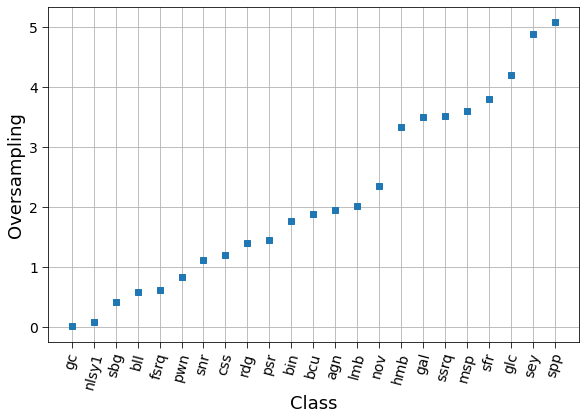

In [43]:
#pl = pyplot.figure()
fig, ax = pyplot.subplots(figsize=(9, 6))
pyplot.plot(os_df, ls='', marker='s')
xticks = ax.get_xticks()
ax.set_xticks(ticks=xticks, labels=os_df.index, rotation=75)
pyplot.xlabel('Class')
pyplot.ylabel('Oversampling')
pyplot.grid()

In [44]:
horiz_trees[0]

['00', '01']

In [45]:
subtree

['00', '01']

In [46]:
util.sub_tree2tree_cat_dict(horiz_trees[0], cat_tree, tree_cat_dict, include_parents=True)

{'00': ['bcu',
  'sey',
  'agn',
  'nov',
  'glc',
  'msp',
  'spp',
  'hmb',
  'pwn',
  'sfr',
  'psr',
  'bin',
  'css',
  'fsrq',
  'lmb',
  'nlsy1',
  'ssrq'],
 '01': ['bll', 'snr', 'sbg', 'rdg', 'gal', 'gc']}